In [9]:
import numpy as np
import matplotlib.pyplot as plt
import json
import os

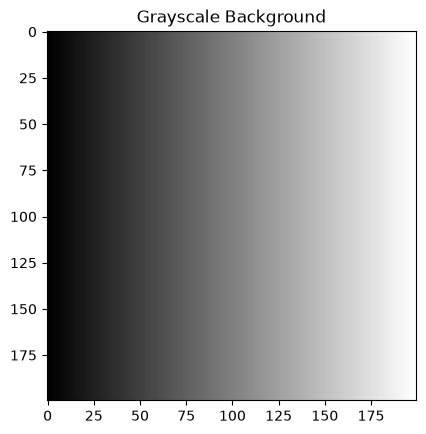

In [10]:
rng = np.random.default_rng(8)

height = width = 200

y, x = np.mgrid[0:height, 0:width]

image = np.tile(
    np.linspace(0.15, 0.40, width),
    (height, 1)
)

plt.imshow(image, cmap="gray")
plt.title("Grayscale Background")
plt.show()

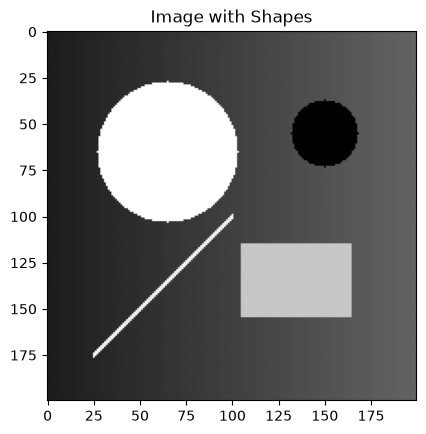

In [11]:
# Bright disk
image[(x - 65)**2 + (y - 65)**2 <= 38**2] = 0.95

# Dark disk
image[(x - 150)**2 + (y - 55)**2 <= 18**2] = 0.05

# Bright rectangle
image[115:155, 105:165] = 0.75

# Diagonal bar
line_mask = (
    (np.abs(y - (200 - x)) <= 1.5)
    & (x >= 25)
    & (x <= 100)
)

image[line_mask] = 0.90

plt.imshow(image, cmap="gray")
plt.title("Image with Shapes")
plt.show()


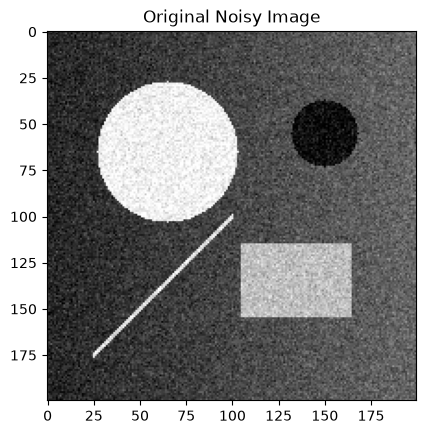

In [15]:
noise = rng.normal(
    0,
    0.07,
    (height, width)
)

original = np.clip(
    image + noise,
    0,
    1
)

plt.imshow(original, cmap="gray")
plt.title("Original Noisy Image")
plt.show()

In [16]:
def convolve2d(img, kernel, padding="reflect"):

    kh, kw = kernel.shape

    padded = np.pad(
        img,
        ((kh // 2, kh // 2),
         (kw // 2, kw // 2)),
        mode=padding
    )

    out = np.zeros_like(img, dtype=float)

    flipped_kernel = kernel[::-1, ::-1]

    for i in range(kh):
        for j in range(kw):

            out += flipped_kernel[i, j] * padded[
                i:i + img.shape[0],
                j:j + img.shape[1]
            ]

    return out

In [17]:
# Box blur: 5 x 5
box_kernel = np.ones((5, 5)) / 25

# Gaussian blur: 7 x 7, sigma 1.4
coords = np.arange(-3, 4)

gx, gy = np.meshgrid(coords, coords)

gaussian_kernel = np.exp(
    -(gx**2 + gy**2) / (2 * 1.4**2)
)

gaussian_kernel /= gaussian_kernel.sum()

# Sobel kernels
sobel_gx = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)

sobel_gy = sobel_gx.T

print("Box kernel:")
print(box_kernel)

print("\nGaussian kernel:")
print(gaussian_kernel)

print("\nSobel Gx:")
print(sobel_gx)

print("\nSobel Gy:")
print(sobel_gy)

Box kernel:
[[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]

Gaussian kernel:
[[0.00084073 0.00301024 0.00647097 0.00835139 0.00647097 0.00301024
  0.00084073]
 [0.00301024 0.01077825 0.02316949 0.02990239 0.02316949 0.01077825
  0.00301024]
 [0.00647097 0.02316949 0.04980635 0.06427974 0.04980635 0.02316949
  0.00647097]
 [0.00835139 0.02990239 0.06427974 0.082959   0.06427974 0.02990239
  0.00835139]
 [0.00647097 0.02316949 0.04980635 0.06427974 0.04980635 0.02316949
  0.00647097]
 [0.00301024 0.01077825 0.02316949 0.02990239 0.02316949 0.01077825
  0.00301024]
 [0.00084073 0.00301024 0.00647097 0.00835139 0.00647097 0.00301024
  0.00084073]]

Sobel Gx:
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Sobel Gy:
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]


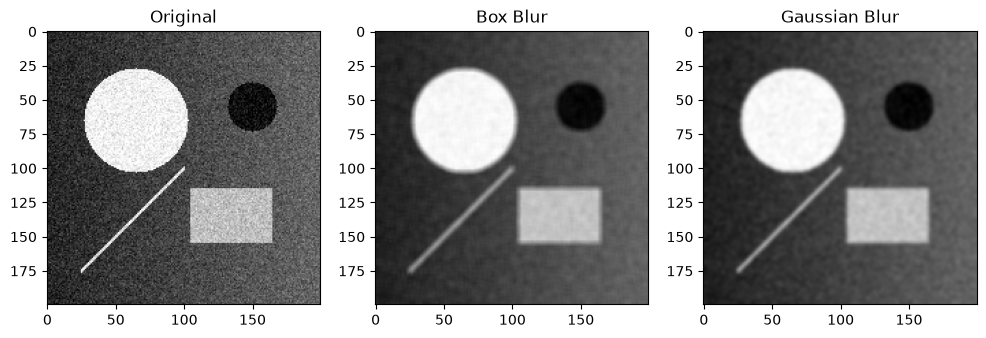

In [18]:
box_blur = convolve2d(
    original,
    box_kernel
)

gaussian_blur = convolve2d(
    original,
    gaussian_kernel
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray")
plt.title("Original")

plt.subplot(1, 3, 2)
plt.imshow(box_blur, cmap="gray")
plt.title("Box Blur")

plt.subplot(1, 3, 3)
plt.imshow(gaussian_blur, cmap="gray")
plt.title("Gaussian Blur")

plt.show()

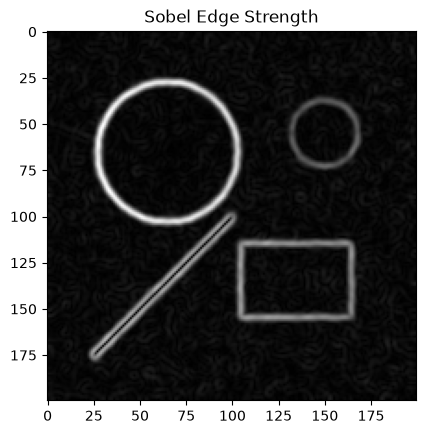

In [19]:
edge_x = convolve2d(
    gaussian_blur,
    sobel_gx
)

edge_y = convolve2d(
    gaussian_blur,
    sobel_gy
)

sobel_edges = np.hypot(
    edge_x,
    edge_y
)

plt.imshow(sobel_edges, cmap="gray")
plt.title("Sobel Edge Strength")
plt.show()

In [20]:
patch = np.s_[10:30, 10:40]

noise_before = float(np.std(original[patch]))
noise_box = float(np.std(box_blur[patch]))
noise_gaussian = float(np.std(gaussian_blur[patch]))

mean_original = float(original.mean())
mean_box = float(box_blur.mean())
mean_gaussian = float(gaussian_blur.mean())

peak = float(sobel_edges.max())

percent_edges = float(
    np.mean(sobel_edges > 0.30 * peak) * 100
)

print("Noise before:", noise_before)
print("Noise after box blur:", noise_box)
print("Noise after Gaussian blur:", noise_gaussian)

print("Mean original:", mean_original)
print("Mean box blur:", mean_box)
print("Mean Gaussian blur:", mean_gaussian)

print("Sobel peak:", peak)
print("Percentage of pixels above threshold:", percent_edges)

Noise before: 0.0687827035927116
Noise after box blur: 0.019043895331839276
Noise after Gaussian blur: 0.019384808228307977
Mean original: 0.37781402219964766
Mean box blur: 0.3778048995075539
Mean Gaussian blur: 0.37780271478920446
Sobel peak: 1.6421844989152325
Percentage of pixels above threshold: 6.455


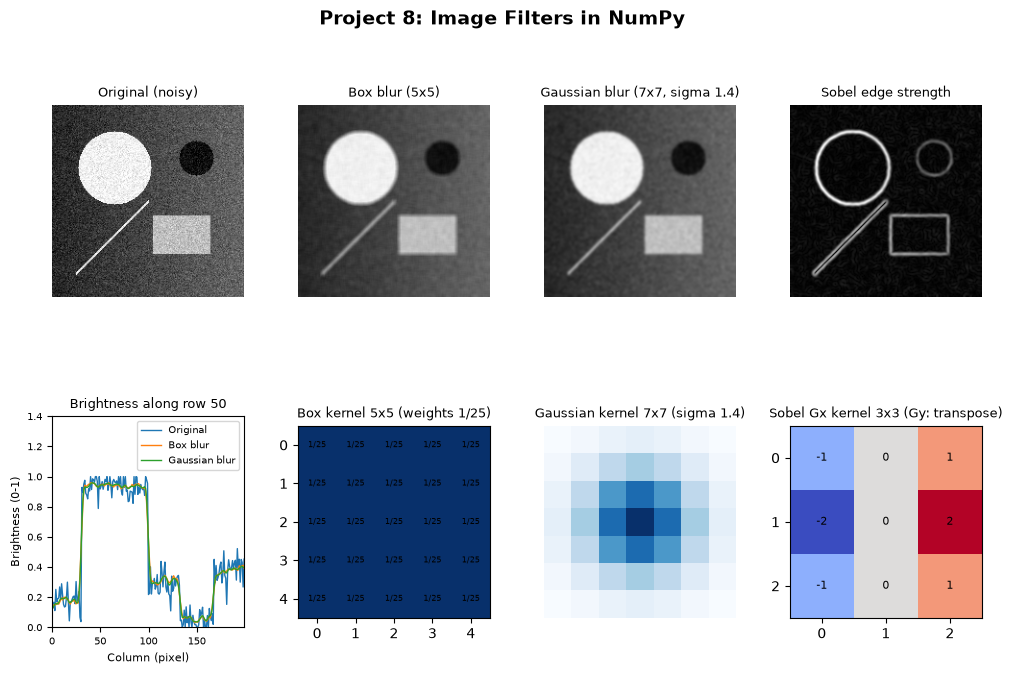

In [22]:
fig = plt.figure(figsize=(12, 7.1))

gs = fig.add_gridspec(
    2,
    4,
    height_ratios=[1.05, 0.92],
    hspace=0.42,
    wspace=0.28
)

titles = [
    "Original (noisy)",
    "Box blur (5x5)",
    "Gaussian blur (7x7, sigma 1.4)",
    "Sobel edge strength"
]

images = [
    original,
    box_blur,
    gaussian_blur,
    sobel_edges
]

# First row: images
for idx, (title, data) in enumerate(zip(titles, images)):

    ax = fig.add_subplot(gs[0, idx])

    ax.imshow(
        data,
        cmap="gray",
        vmin=0,
        vmax=1 if idx < 3 else max(peak, 1)
    )

    ax.set_title(title, fontsize=9)
    ax.axis("off")


# Second row: brightness profile
ax = fig.add_subplot(gs[1, 0])

row = 50

ax.plot(original[row], label="Original", lw=1)
ax.plot(box_blur[row], label="Box blur", lw=1)
ax.plot(gaussian_blur[row], label="Gaussian blur", lw=1)

ax.set_title("Brightness along row 50", fontsize=9)
ax.set_xlabel("Column (pixel)", fontsize=8)
ax.set_ylabel("Brightness (0-1)", fontsize=8)
ax.set_xlim(0, 199)
ax.set_ylim(0, 1.4)
ax.tick_params(labelsize=7)
ax.legend(fontsize=7)


# Box kernel
ax = fig.add_subplot(gs[1, 1])

ax.imshow(box_kernel, cmap="Blues", vmin=0, vmax=0.04)

ax.set_title("Box kernel 5x5 (weights 1/25)", fontsize=9)
ax.set_xticks(range(5))
ax.set_yticks(range(5))

for i in range(5):
    for j in range(5):
        ax.text(
            j, i, "1/25",
            ha="center",
            va="center",
            fontsize=6
        )


# Gaussian kernel
ax = fig.add_subplot(gs[1, 2])

ax.imshow(gaussian_kernel, cmap="Blues")
ax.set_title("Gaussian kernel 7x7 (sigma 1.4)", fontsize=9)
ax.axis("off")


# Sobel kernel
ax = fig.add_subplot(gs[1, 3])

ax.imshow(sobel_gx, cmap="coolwarm", vmin=-2, vmax=2)

ax.set_title("Sobel Gx kernel 3x3 (Gy: transpose)", fontsize=9)
ax.set_xticks(range(3))
ax.set_yticks(range(3))

for i in range(3):
    for j in range(3):
        ax.text(
            j, i, f"{sobel_gx[i, j]:g}",
            ha="center",
            va="center",
            fontsize=8
        )


fig.suptitle(
    "Project 8: Image Filters in NumPy",
    fontsize=14,
    fontweight="bold"
)

plt.show()